<a href="https://colab.research.google.com/github/teresacasbusquet-hue/historico-clasicos/blob/main/Pruebas_API_football_Statsbomb_pruebas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**EXPLORAR SI EN API SPORTS HAY DATOS DE LA ÚLTIMA TEMPORADA DE LA LIGA**


In [ ]:
import requests
import pandas as pd

API_KEY = "5b426102c7e0dec302c53f3f59873c6c"
URL_BASE = "https://v3.football.api-sports.io"
cabeceras = {"x-apisports-key": API_KEY}

In [ ]:
r = requests.get(f"{URL_BASE}/status", headers=cabeceras)
r.json()

{'get': 'status',
 'parameters': [],
 'errors': [],
 'results': 0,
 'paging': {'current': 1, 'total': 1},
 'response': {'account': {'firstname': 'Teresa',
   'lastname': 'Casañas',
   'email': 'teresa.cas.busquet@gmail.com'},
  'subscription': {'plan': 'Free',
   'end': '2027-11-21T00:00:00+00:00',
   'active': True},
  'requests': {'current': 0, 'limit_day': 100}}}

In [ ]:
r = requests.get(f"{URL_BASE}/fixtures/rounds",
                 headers=cabeceras,
                 params={"league": 140, "season": 2025, "current": "true"})
r.json()

{'get': 'fixtures/rounds',
 'parameters': {'league': '140', 'season': '2025', 'current': 'true'},
 'errors': {'plan': 'Free plans do not have access to this season, try from 2022 to 2024.'},
 'results': 0,
 'paging': {'current': 1, 'total': 1},
 'response': []}

**Ejercicio 1 · Mapa de tiros con xG de un Clásico (StatsBomb)**

**Paso 1 · Instalar las librerías**

El ! al principio le dice a Colab que es una instrucción de instalación, no código Python. Solo hace falta una vez por sesión.

In [ ]:
!pip install statsbombpy mplsoccer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [mplsoccer]


**Paso 2 · Ver qué temporadas de LaLiga hay**

✅ Tienen que salir las temporadas de 2004/2005 a 2020/2021 (más una de 1973/74). Apunta dos números: LaLiga es la competición 11 y la 2010/2011 es la temporada 22.

Saldrá un aviso: "credentials were not supplied. open data access only". Es normal: significa que usas los datos gratuitos, sin cuenta de pago.



In [ ]:
from statsbombpy import sb

competiciones = sb.competitions()
competiciones[competiciones["competition_name"] == "La Liga"][["competition_id", "season_id", "season_name"]]

/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


,competition_id,season_id,season_name
40,11,90,2020/2021
41,11,42,2019/2020
42,11,4,2018/2019
43,11,1,2017/2018
44,11,2,2016/2017
45,11,27,2015/2016
46,11,26,2014/2015
47,11,25,2013/2014
48,11,24,2012/2013
49,11,23,2011/2012


**Paso 3 · Encontrar el Clásico**

✅ Tienen que salir 2 partidos. El que buscamos es el 69299 (29/11/2010, Barcelona 5-0 Real Madrid).

Fíjate en que es el mismo filtro con isin y & que hiciste en la tarea, pero en Pandas en lugar de PySpark.

In [ ]:
partidos = sb.matches(competition_id=11, season_id=22)

clasicos = partidos[partidos["home_team"].isin(["Barcelona", "Real Madrid"]) &
                    partidos["away_team"].isin(["Barcelona", "Real Madrid"])]
clasicos[["match_id", "match_date", "home_team", "away_team", "home_score", "away_score"]]

/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


,match_id,match_date,home_team,away_team,home_score,away_score
10,69245,2011-04-16,Real Madrid,Barcelona,1,1
27,69299,2010-11-29,Barcelona,Real Madrid,5,0


**Paso 4 · Descargar todos los eventos del partido**

✅ Tiene que salir (3975, 96): casi 4.000 acciones del partido, cada una con 96 columnas de información. Esto es lo que API-Football no tiene.

In [ ]:
eventos = sb.events(match_id=69299)
eventos.shape

/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


(3975, 96)

**Paso 5 · Quedarse con los tiros y preparar las coordenadas**

La columna location guarda cada posición como una lista [x, y]. Con .str[0] y .str[1] la separamos en dos columnas.
gol es una columna nueva de tipo verdadero/falso (Boolean).
El groupby + agg es el mismo concepto que en PySpark.

Tiene que salir: Barcelona 14 tiros, 5 goles, 2,77 xG y Real Madrid 5 tiros, 0 goles, 0,13 xG.

Esa tabla ya cuenta una historia: el Barça "debía" marcar unos 3 goles con sus ocasiones y marcó 5, y el Madrid apenas generó peligro.

In [ ]:
tiros = eventos[eventos["type"] == "Shot"].copy()

tiros["x"] = tiros["location"].str[0]
tiros["y"] = tiros["location"].str[1]
tiros["gol"] = tiros["shot_outcome"] == "Goal"

tiros.groupby("team").agg(tiros=("id", "count"),
                          goles=("gol", "sum"),
                          xG=("shot_statsbomb_xg", "sum")).round(2)

,tiros,goles,xG
team,,,
Barcelona,14,5,2.77
Real Madrid,5,0,0.13


**Paso 6 · Dibujar el mapa de tiros**

half=True dibuja solo medio campo: el área rival es donde están los tiros.
s= es el tamaño del punto: cuanto más xG, más grande.
~ significa "no": ~barca["gol"] son los tiros que no fueron gol.
A diferencia del notebook de la clase, aquí el título se calcula con los datos (len, .sum()), no se escribe a mano.

✅ El círculo rojo más grande, pegado a la portería, es el gol de Pedro (xG 0,90). Los otros goles son de Xavi, Villa (dos) y Jeffren.

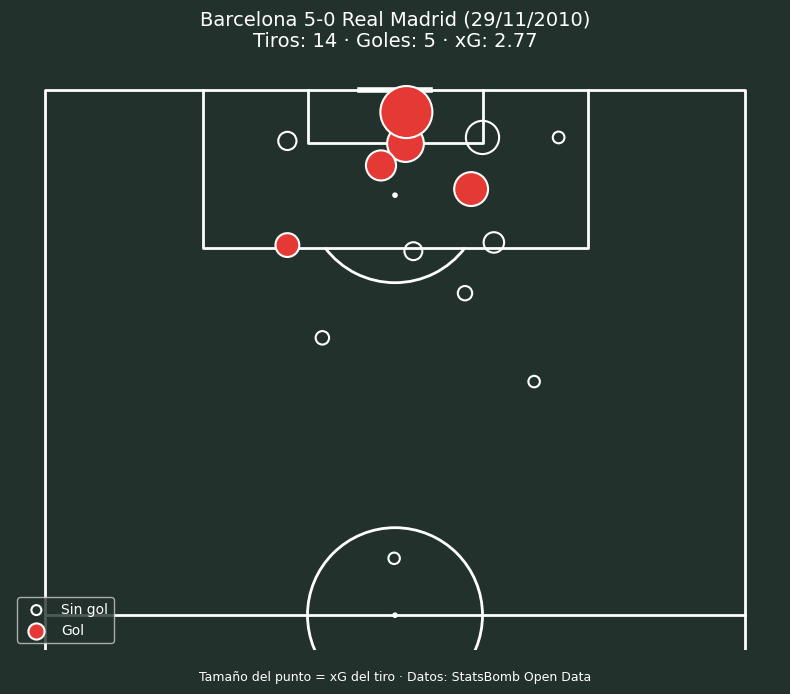

In [ ]:
import matplotlib.pyplot as plt
from mplsoccer import VerticalPitch

barca = tiros[tiros["team"] == "Barcelona"]
sin_gol = barca[~barca["gol"]]
con_gol = barca[barca["gol"]]

pitch = VerticalPitch(pitch_type="statsbomb", half=True,
                      pitch_color="#22312b", line_color="white")
fig, ax = pitch.draw(figsize=(8, 7))
fig.set_facecolor("#22312b")

pitch.scatter(sin_gol["x"], sin_gol["y"], s=sin_gol["shot_statsbomb_xg"] * 1500 + 60,
              c="none", edgecolors="white", lw=1.5, ax=ax, label="Sin gol")
pitch.scatter(con_gol["x"], con_gol["y"], s=con_gol["shot_statsbomb_xg"] * 1500 + 60,
              c="#e53935", edgecolors="white", lw=1.5, ax=ax, label="Gol")

ax.set_title(f"Barcelona 5-0 Real Madrid (29/11/2010)\n"
             f"Tiros: {len(barca)} · Goles: {con_gol.shape[0]} · xG: {barca['shot_statsbomb_xg'].sum():.2f}",
             color="white", fontsize=14)
ax.legend(loc="lower left", facecolor="#22312b", labelcolor="white", markerscale=0.4)
fig.text(0.5, 0.02, "Tamaño del punto = xG del tiro · Datos: StatsBomb Open Data",
         color="white", ha="center", fontsize=9)
plt.show()

**Ejercicio 2 · Estadísticas de jugadores de un Clásico 2024-25 (API-Football)**

In [ ]:
import requests
import pandas as pd

API_KEY = "5b426102c7e0dec302c53f3f59873c6c"
URL_BASE = "https://v3.football.api-sports.io"
cabeceras = {"x-apisports-key": API_KEY}

**Paso 2 · Descargar todos los partidos de LaLiga 2024-25 (1 consulta)**

✅ errors tiene que salir vacío y results tiene que ser 380 (los 380 partidos de la temporada).

In [ ]:
r = requests.get(f"{URL_BASE}/fixtures", headers=cabeceras,
                 params={"league": 140, "season": 2024})
datos = r.json()
print(datos["errors"], datos["results"])

[] 380


**Paso 3 · Convertir a tabla y buscar los Clásicos**

pd.json_normalize "aplana" el JSON anidado. Por eso las columnas se llaman con puntos, como teams.home.name.

✅ Tienen que salir 2 partidos: Real Madrid 0-4 Barcelona (octubre de 2024) y Barcelona 4-3 Real Madrid (mayo de 2025). Copia el fixture.id del que quieras analizar.

In [ ]:
partidos = pd.json_normalize(datos["response"])

clasicos = partidos[partidos["teams.home.name"].isin(["Barcelona", "Real Madrid"]) &
                    partidos["teams.away.name"].isin(["Barcelona", "Real Madrid"])]
clasicos[["fixture.id", "fixture.date", "teams.home.name", "teams.away.name", "goals.home", "goals.away"]]

,fixture.id,fixture.date,teams.home.name,teams.away.name,goals.home,goals.away
104,1208587,2024-10-26T19:00:00+00:00,Real Madrid,Barcelona,0,4
347,1208801,2025-05-11T14:15:00+00:00,Barcelona,Real Madrid,4,3


**Paso 4 · Descargar las estadísticas de los jugadores (1 consulta)**

✅ results tiene que ser 2: un bloque por equipo.

In [ ]:
ID_PARTIDO = 1208801   # ← sustituye por el fixture.id del paso 3

r = requests.get(f"{URL_BASE}/fixtures/players", headers=cabeceras,
                 params={"fixture": ID_PARTIDO})
datos_jug = r.json()
print(datos_jug["errors"], datos_jug["results"])

[] 2


**Paso 5 · Construir la tabla de jugadores**

El JSON viene anidado en dos niveles: equipos y, dentro, jugadores. Los dos for recorren cada nivel y guardan una fila por jugador.
La nota viene como texto ("7.8"), así que la convertimos a número con pd.to_numeric.
fillna(0): los suplentes que no jugaron traen None. Es lo mismo que el ejercicio 9 de tu tarea.

✅ Tiene que salir una tabla con los 10 mejores del partido según la nota de API-Football.

In [ ]:
filas = []
for equipo in datos_jug["response"]:
    for j in equipo["players"]:
        e = j["statistics"][0]
        filas.append({
            "equipo":       equipo["team"]["name"],
            "jugador":      j["player"]["name"],
            "minutos":      e["games"]["minutes"],
            "nota":         e["games"]["rating"],
            "tiros":        e["shots"]["total"],
            "goles":        e["goals"]["total"],
            "asistencias":  e["goals"]["assists"],
            "pases_clave":  e["passes"]["key"],
            "duelos_gan":   e["duels"]["won"],
            "regates_ok":   e["dribbles"]["success"],
        })

jugadores = pd.DataFrame(filas)
jugadores["nota"] = pd.to_numeric(jugadores["nota"])
jugadores = jugadores.fillna(0)
jugadores.sort_values("nota", ascending=False).head(10)

,equipo,jugador,minutos,nota,tiros,goles,asistencias,pases_clave,duelos_gan,regates_ok
7,Barcelona,Lamine Yamal,90.0,9.2,6.0,1.0,0.0,3.0,6.0,4.0
33,Real Madrid,Kylian Mbappé,90.0,8.9,5.0,3.0,0.0,1.0,2.0,0.0
10,Barcelona,Ferran Torres,89.0,8.0,1.0,0.0,3.0,3.0,5.0,1.0
6,Barcelona,Pedri,90.0,7.6,0.0,0.0,1.0,3.0,7.0,1.0
32,Real Madrid,Vinícius Júnior,88.0,7.6,1.0,0.0,2.0,3.0,4.0,0.0
34,Real Madrid,Luka Modrić,45.0,7.3,0.0,0.0,0.0,2.0,2.0,1.0
9,Barcelona,Raphinha,90.0,7.3,6.0,2.0,0.0,3.0,0.0,0.0
5,Barcelona,Frenkie de Jong,90.0,7.2,0.0,0.0,0.0,0.0,6.0,0.0
1,Barcelona,Eric García,77.0,7.2,1.0,1.0,0.0,0.0,6.0,0.0
25,Real Madrid,Aurélien Tchouaméni,90.0,6.9,0.0,0.0,0.0,0.0,5.0,0.0


In [ ]:
cols = ["minutos", "tiros", "goles", "asistencias", "pases_clave", "duelos_gan", "regates_ok"]
jugadores[cols] = jugadores[cols].astype(int)

Qué hace cada parte:

metricas y etiquetas son dos listas en el mismo orden: el nombre de la columna en la tabla y el texto que se ve en el gráfico.
maximos fija el borde de cada eje en el valor más alto del partido. Así cada métrica se compara con lo mejor que hubo en ese Clásico. El max(..., 1) evita que un eje se quede a 0 si nadie tiene ninguna acción de ese tipo.
.iloc[0].tolist() coge la fila del jugador y la convierte en una lista de números, que es el formato que pide el radar.
El filtro por nombre tiene que coincidir letra por letra, con tildes incluidas: "Kylian Mbappé" con é. Si sale el error IndexError: single positional indexer is out-of-bounds, el nombre no coincide; cópialo tal cual de la tabla.

Lo que se lee en el radar:

Lamine Yamal (granate) ocupa casi todo el gráfico: el máximo del partido en tiros, regates y pases clave, y casi el máximo en duelos ganados.
Mbappé (amarillo) tiene una forma estrecha y muy dirigida a puerta: el máximo en goles (3) con 5 tiros, pero apenas participa en el resto del juego.

Son dos perfiles muy distintos en el mismo partido, y este tipo de comparación funciona bien en una cuenta de X. Para compararlo con cualquier otro jugador, cambia los nombres en j1 y j2.

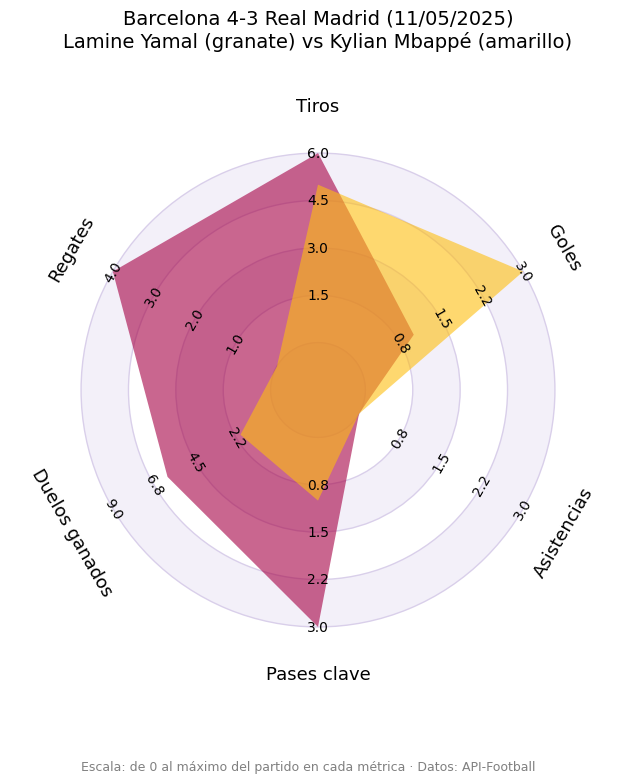

In [ ]:
from mplsoccer import Radar
import matplotlib.pyplot as plt

metricas  = ["tiros", "goles", "asistencias", "pases_clave", "duelos_gan", "regates_ok"]
etiquetas = ["Tiros", "Goles", "Asistencias", "Pases clave", "Duelos ganados", "Regates"]

minimos = [0] * len(metricas)
maximos = [max(jugadores[m].max(), 1) for m in metricas]

j1 = jugadores[jugadores["jugador"] == "Lamine Yamal"][metricas].iloc[0].tolist()
j2 = jugadores[jugadores["jugador"] == "Kylian Mbappé"][metricas].iloc[0].tolist()

radar = Radar(etiquetas, minimos, maximos,
              num_rings=4, ring_width=1, center_circle_radius=1)
fig, ax = radar.setup_axis(figsize=(8, 8))
radar.draw_circles(ax=ax, facecolor="#f3f0f9", edgecolor="#d9cfea")
radar.draw_radar_compare(j1, j2, ax=ax,
                         kwargs_radar={"facecolor": "#a50044", "alpha": 0.6},
                         kwargs_compare={"facecolor": "#febe10", "alpha": 0.6})
radar.draw_range_labels(ax=ax, fontsize=10)
radar.draw_param_labels(ax=ax, fontsize=13)
ax.set_title("Barcelona 4-3 Real Madrid (11/05/2025)\n"
             "Lamine Yamal (granate) vs Kylian Mbappé (amarillo)", fontsize=14, pad=25)
fig.text(0.5, 0.02, "Escala: de 0 al máximo del partido en cada métrica · Datos: API-Football",
         ha="center", fontsize=9, color="gray")
plt.show()

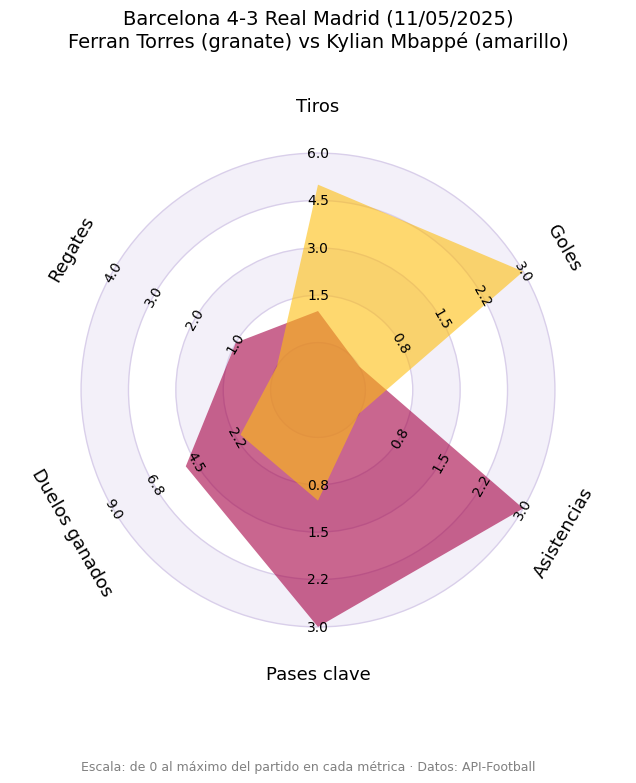

In [ ]:
from mplsoccer import Radar
import matplotlib.pyplot as plt

metricas  = ["tiros", "goles", "asistencias", "pases_clave", "duelos_gan", "regates_ok"]
etiquetas = ["Tiros", "Goles", "Asistencias", "Pases clave", "Duelos ganados", "Regates"]

minimos = [0] * len(metricas)
maximos = [max(jugadores[m].max(), 1) for m in metricas]

j1 = jugadores[jugadores["jugador"] == "Ferran Torres"][metricas].iloc[0].tolist()
j2 = jugadores[jugadores["jugador"] == "Kylian Mbappé"][metricas].iloc[0].tolist()

radar = Radar(etiquetas, minimos, maximos,
              num_rings=4, ring_width=1, center_circle_radius=1)
fig, ax = radar.setup_axis(figsize=(8, 8))
radar.draw_circles(ax=ax, facecolor="#f3f0f9", edgecolor="#d9cfea")
radar.draw_radar_compare(j1, j2, ax=ax,
                         kwargs_radar={"facecolor": "#a50044", "alpha": 0.6},
                         kwargs_compare={"facecolor": "#febe10", "alpha": 0.6})
radar.draw_range_labels(ax=ax, fontsize=10)
radar.draw_param_labels(ax=ax, fontsize=13)
ax.set_title("Barcelona 4-3 Real Madrid (11/05/2025)\n"
             "Ferran Torres (granate) vs Kylian Mbappé (amarillo)", fontsize=14, pad=25)
fig.text(0.5, 0.02, "Escala: de 0 al máximo del partido en cada métrica · Datos: API-Football",
         ha="center", fontsize=9, color="gray")
plt.show()

Lo que muestra:

Mbappé (amarillo) es un nueve finalizador: 5 tiros, 3 goles, ninguna asistencia y apenas participa en el juego.
Ferran Torres (granate) es un nueve asociativo: 1 solo tiro y ningún gol, pero 3 asistencias y 3 pases clave (el máximo del partido) y 5 duelos ganados.

Los dos influyeron mucho en el resultado, pero por caminos opuestos: uno marca y el otro hace marcar.

**Paso 1 · Descargar las alineaciones**

✅ results tiene que ser 2, y debajo saldrá el sistema de cada equipo, por ejemplo 4-2-3-1 o 4-3-3.

In [ ]:
r = requests.get(f"{URL_BASE}/fixtures/lineups", headers=cabeceras,
                 params={"fixture": ID_PARTIDO})
alineaciones = r.json()
print(alineaciones["errors"], alineaciones["results"])

for equipo in alineaciones["response"]:
    print(equipo["team"]["name"], "→ sistema:", equipo["formation"])

[] 2
Barcelona → sistema: 4-2-3-1
Real Madrid → sistema: 4-2-3-1


**Paso 2 · Tabla de titulares con su casilla**

grid viene como texto, por ejemplo "4:2". El primer número es la línea del campo (1 = portero, 2 = defensas… y la última = delanteros) y el segundo, la posición dentro de esa línea.
.str.split(":", expand=True) separa ese texto en dos columnas y .astype(int) las convierte en números.

In [ ]:
filas = []
for equipo in alineaciones["response"]:
    for j in equipo["startXI"]:
        p = j["player"]
        filas.append({
            "equipo":  equipo["team"]["name"],
            "sistema": equipo["formation"],
            "jugador": p["name"],
            "dorsal":  p["number"],
            "pos":     p["pos"],
            "grid":    p["grid"],
        })

titulares = pd.DataFrame(filas)
titulares[["linea", "columna"]] = titulares["grid"].str.split(":", expand=True).astype(int)
titulares

,equipo,sistema,jugador,dorsal,pos,grid,linea,columna
0,Barcelona,4-2-3-1,W. Szczęsny,25,G,1:1,1,1
1,Barcelona,4-2-3-1,Eric García,24,D,2:4,2,4
2,Barcelona,4-2-3-1,Pau Cubarsí,2,D,2:3,2,3
3,Barcelona,4-2-3-1,Iñigo Martínez,5,D,2:2,2,2
4,Barcelona,4-2-3-1,Gerard Martín,35,D,2:1,2,1
5,Barcelona,4-2-3-1,F. de Jong,21,M,3:2,3,2
6,Barcelona,4-2-3-1,Pedri,8,M,3:1,3,1
7,Barcelona,4-2-3-1,Lamine Yamal,19,M,4:3,4,3
8,Barcelona,4-2-3-1,Dani Olmo,20,M,4:2,4,2
9,Barcelona,4-2-3-1,Raphinha,11,M,4:1,4,1


**Paso 3 · Ver la delantera de cada equipo**

transform("max") calcula la línea más adelantada de cada equipo y la pone al lado de cada jugador, para poder filtrar la última línea de los dos equipos a la vez.

Cómo leer el resultado

Si la delantera tiene 3 jugadores (un 4-3-3), el que tiene la columna 2 es el del centro. Así sabrás si Ferran era el nueve, con Yamal y Raphinha en las bandas.
Si tiene 1 jugador (un 4-2-3-1), ese es el delantero centro.
Si tiene 2 jugadores (un 4-4-2), los dos son delanteros. En ese caso Mbappé compartiría la punta, probablemente con Vinícius, y no sería "el" nueve en solitario.

Dos limitaciones

Es la posición en la alineación inicial, la que entrega el club antes del partido. No recoge los cambios tácticos durante el partido ni los movimientos reales: un nueve puede pasar media parte cayendo a banda.
Para saber dónde jugó de verdad, haría falta la posición de cada acción (coordenadas). Con eso harías el mapa de calor de cada jugador, como en la clase, pero eso solo lo tienen StatsBomb y los proveedores de pago, no API-Football.

In [ ]:
ultima = titulares.groupby("equipo")["linea"].transform("max")
titulares[titulares["linea"] == ultima][["equipo", "sistema", "jugador", "pos", "grid"]]

,equipo,sistema,jugador,pos,grid
10,Barcelona,4-2-3-1,Ferran Torres,F,5:1
21,Real Madrid,4-2-3-1,K. Mbappé,F,5:1


In [1]:
from google.colab import userdata; API_KEY = userdata.get('API_FOOTBALL_KEY')


In [1]:
!pip install -q statsbombpy mplsoccer

from google.colab import drive
drive.mount('/content/drive')

import os
BASE = '/content/drive/MyDrive/Historico_Clasicos'   # cambia el nombre si prefieres otro
for sub in ['datos/statsbomb/eventos', 'datos/api_football', 'graficos']:
    os.makedirs(f'{BASE}/{sub}', exist_ok=True)

print(sorted(os.listdir(BASE)))
print(sorted(os.listdir(f'{BASE}/datos')))

Mounted at /content/drive
['datos', 'graficos', 'inventario_clasicos_statsbomb.csv']
['api_football', 'statsbomb']


In [2]:
import os, warnings
import pandas as pd
from statsbombpy import sb
warnings.filterwarnings('ignore')   # quita el aviso "credentials were not supplied" (es normal con Open Data)

BASE = '/content/drive/MyDrive/Historico_Clasicos'

# Todas las temporadas de Liga y Copa del Rey que hay en StatsBomb Open Data
comps = sb.competitions()
temporadas = comps[comps['competition_name'].isin(['La Liga', 'Copa del Rey'])]
partidos = pd.concat(
    [sb.matches(competition_id=c.competition_id, season_id=c.season_id) for c in temporadas.itertuples()],
    ignore_index=True)

# Nos quedamos con los Barça-Real Madrid
equipos = ['Barcelona', 'Real Madrid']
clasicos = (partidos[partidos['home_team'].isin(equipos) & partidos['away_team'].isin(equipos)]
            .sort_values('match_date', ascending=False)
            [['match_date', 'competition', 'season', 'home_team', 'away_team',
              'home_score', 'away_score', 'match_id']]
            .reset_index(drop=True))

print(len(temporadas), 'temporadas revisadas ->', len(clasicos), 'Clásicos')

# Comparar con el inventario que subiste
inv = pd.read_csv(f'{BASE}/inventario_clasicos_statsbomb.csv')
print('Mismos match_id que el CSV:', set(clasicos['match_id']) == set(inv['match_id']))
clasicos.head()

21 temporadas revisadas -> 31 Clásicos
Mismos match_id que el CSV: True


,match_date,competition,season,home_team,away_team,home_score,away_score,match_id
0,2021-04-10,Spain - La Liga,2020/2021,Real Madrid,Barcelona,2,1,3773497
1,2020-10-24,Spain - La Liga,2020/2021,Barcelona,Real Madrid,1,3,3773585
2,2020-03-01,Spain - La Liga,2019/2020,Real Madrid,Barcelona,2,0,303470
3,2019-12-18,Spain - La Liga,2019/2020,Barcelona,Real Madrid,0,0,303596
4,2019-03-02,Spain - La Liga,2018/2019,Real Madrid,Barcelona,0,1,16196


In [4]:
CARPETA = f'{BASE}/datos/statsbomb/eventos'
os.makedirs(CARPETA, exist_ok=True)

todos = []
for p in inv.itertuples():
    ev = sb.events(match_id=p.match_id)
    ev.to_parquet(f'{CARPETA}/{p.match_id}.parquet', index=False)  # un fichero por partido
    todos.append(ev)
    print(p.fecha, p.local, p.goles_local, '-', p.goles_visitante, p.visitante, '->', len(ev), 'eventos')

eventos = pd.concat(todos, ignore_index=True)
eventos.to_parquet(f'{BASE}/datos/statsbomb/eventos_clasicos.parquet', index=False)  # los 31 juntos

print('\nPartidos:', eventos['match_id'].nunique())
print('Eventos totales:', len(eventos))
print('Ficheros en la carpeta:', len(os.listdir(CARPETA)))

2021-04-10 Real Madrid 2 - 1 Barcelona -> 3991 eventos
2020-10-24 Barcelona 1 - 3 Real Madrid -> 4213 eventos
2020-03-01 Real Madrid 2 - 0 Barcelona -> 4227 eventos
2019-12-18 Barcelona 0 - 0 Real Madrid -> 4158 eventos
2019-03-02 Real Madrid 0 - 1 Barcelona -> 3978 eventos
2018-05-06 Barcelona 2 - 2 Real Madrid -> 3831 eventos
2017-12-23 Real Madrid 0 - 3 Barcelona -> 4101 eventos
2017-04-23 Real Madrid 2 - 3 Barcelona -> 3667 eventos
2016-12-03 Barcelona 1 - 1 Real Madrid -> 3979 eventos
2016-04-02 Barcelona 1 - 2 Real Madrid -> 3700 eventos
2015-11-21 Real Madrid 0 - 4 Barcelona -> 3860 eventos
2015-03-22 Barcelona 2 - 1 Real Madrid -> 3823 eventos
2014-10-25 Real Madrid 3 - 1 Barcelona -> 3839 eventos
2014-03-23 Real Madrid 3 - 4 Barcelona -> 3905 eventos
2013-10-26 Barcelona 2 - 1 Real Madrid -> 3693 eventos
2013-03-02 Real Madrid 2 - 1 Barcelona -> 3867 eventos
2012-10-07 Barcelona 2 - 2 Real Madrid -> 3675 eventos
2012-04-21 Barcelona 1 - 2 Real Madrid -> 3616 eventos
2011-12-10

In [5]:
# Un gol es un tiro con resultado "Goal" o un evento "Own Goal For" (gol en propia, se apunta al equipo que se beneficia)
goles = eventos[((eventos['type'] == 'Shot') & (eventos['shot_outcome'] == 'Goal'))
                | (eventos['type'] == 'Own Goal For')]

def contar(match_id, equipo):
    return int(((goles['match_id'] == match_id) & (goles['team'] == equipo)).sum())

inv['gl_eventos'] = [contar(m, e) for m, e in zip(inv['match_id'], inv['local'])]
inv['gv_eventos'] = [contar(m, e) for m, e in zip(inv['match_id'], inv['visitante'])]
inv['cuadra'] = (inv['gl_eventos'] == inv['goles_local']) & (inv['gv_eventos'] == inv['goles_visitante'])

print('Partidos que cuadran:', inv['cuadra'].sum(), 'de', len(inv))
print('Goles contados en los eventos:', len(goles))
print('Goles según los resultados:', (inv['goles_local'] + inv['goles_visitante']).sum())
inv[~inv['cuadra']]   # partidos que NO cuadran (debería salir vacío)

Partidos que cuadran: 31 de 31
Goles contados en los eventos: 106
Goles según los resultados: 106


,fecha,competicion,temporada,local,visitante,goles_local,goles_visitante,match_id,eventos,fuente,gl_eventos,gv_eventos,cuadra


In [7]:
import requests, json
from google.colab import userdata

API_KEY = userdata.get('API_FOOTBALL_KEY').strip()
URL = 'https://v3.football.api-sports.io'
H = {'x-apisports-key': API_KEY}

# 1) Estado de la cuenta
s = requests.get(f'{URL}/status', headers=H).json()['response']
print('Plan:', s['subscription']['plan'], '| consultas hoy:', s['requests']['current'], 'de', s['requests']['limit_day'])

# 2) Barça (529) - Real Madrid (541), temporada a temporada
CARPETA_AF = f'{BASE}/datos/api_football'
filas = []
for temporada in [2022, 2023, 2024]:
    d = requests.get(f'{URL}/fixtures/headtohead', headers=H,
                     params={'h2h': '529-541', 'season': temporada}).json()
    with open(f'{CARPETA_AF}/h2h_{temporada}.json', 'w') as f:   # guardamos la respuesta tal cual
        json.dump(d, f)
    if d['errors']:
        print(temporada, '-> ERROR:', d['errors'])
        continue
    for x in d['response']:
        filas.append({'fecha': x['fixture']['date'][:10], 'competicion': x['league']['name'],
                      'ronda': x['league']['round'], 'local': x['teams']['home']['name'],
                      'visitante': x['teams']['away']['name'], 'goles_local': x['goals']['home'],
                      'goles_visitante': x['goals']['away'], 'fixture_id': x['fixture']['id']})

inv_af = pd.DataFrame(filas).sort_values('fecha', ascending=False).reset_index(drop=True)
print(len(inv_af), 'partidos encontrados')
inv_af

Plan: Free | consultas hoy: 0 de 100
16 partidos encontrados


,fecha,competicion,ronda,local,visitante,goles_local,goles_visitante,fixture_id
0,2025-05-11,La Liga,Regular Season - 35,Barcelona,Real Madrid,4,3,1208801
1,2025-04-26,Copa del Rey,Final,Barcelona,Real Madrid,3,2,1367758
2,2025-01-12,Super Cup,Final,Real Madrid,Barcelona,2,5,1334517
3,2024-10-26,La Liga,Regular Season - 11,Real Madrid,Barcelona,0,4,1208587
4,2024-08-03,Friendlies Clubs,Club Friendlies 5,Barcelona,Real Madrid,2,1,1277934
5,2024-04-21,La Liga,Regular Season - 32,Real Madrid,Barcelona,3,2,1038267
6,2024-01-14,Super Cup,Final,Real Madrid,Barcelona,4,1,1159314
7,2023-10-28,La Liga,Regular Season - 11,Barcelona,Real Madrid,1,2,1038054
8,2023-07-29,Friendlies Clubs,Club Friendlies 1,Barcelona,Real Madrid,3,0,1117081
9,2023-07-29,Friendlies Clubs,Club Friendlies 5,Real Madrid,Barcelona,0,3,1097382


In [8]:
oficiales = inv_af[inv_af['competicion'] != 'Friendlies Clubs'].reset_index(drop=True)
oficiales['fuente'] = 'API-Football'

print(len(oficiales), 'Clásicos oficiales')
print(oficiales['competicion'].value_counts())

oficiales.to_csv(f'{CARPETA_AF}/inventario_clasicos_apifootball.csv', index=False)
print(sorted(os.listdir(CARPETA_AF)))

12 Clásicos oficiales
competicion
La Liga         6
Copa del Rey    3
Super Cup       3
Name: count, dtype: int64
['h2h_2022.json', 'h2h_2023.json', 'h2h_2024.json', 'inventario_clasicos_apifootball.csv']


In [9]:
import time
CARPETA_STATS = f'{CARPETA_AF}/estadisticas'
os.makedirs(CARPETA_STATS, exist_ok=True)

filas = []
for p in oficiales.itertuples():
    ruta = f'{CARPETA_STATS}/{p.fixture_id}.json'
    if os.path.exists(ruta):                      # ya descargado: no gastamos consulta
        with open(ruta) as f:
            d = json.load(f)
    else:
        d = requests.get(f'{URL}/fixtures/statistics', headers=H,
                         params={'fixture': p.fixture_id}).json()
        if d['errors']:
            print(p.fixture_id, '-> ERROR:', d['errors'])
            continue
        with open(ruta, 'w') as f:                # guardamos la respuesta tal cual
            json.dump(d, f)
        time.sleep(7)                             # pausa por el límite de consultas por minuto
    for eq in d['response']:
        fila = {'fixture_id': p.fixture_id, 'fecha': p.fecha,
                'competicion': p.competicion, 'equipo': eq['team']['name']}
        for s in eq['statistics']:
            fila[s['type']] = s['value']
        filas.append(fila)
    print(p.fecha, p.local, p.goles_local, '-', p.goles_visitante, p.visitante, '->', len(d['response']), 'equipos')

stats_af = pd.DataFrame(filas)
stats_af.to_csv(f'{CARPETA_AF}/estadisticas_clasicos_apifootball.csv', index=False)
print('\nFilas:', len(stats_af), '| Columnas:', stats_af.shape[1])
print(list(stats_af.columns))

2025-05-11 Barcelona 4 - 3 Real Madrid -> 2 equipos
2025-04-26 Barcelona 3 - 2 Real Madrid -> 2 equipos
2025-01-12 Real Madrid 2 - 5 Barcelona -> 2 equipos
2024-10-26 Real Madrid 0 - 4 Barcelona -> 2 equipos
2024-04-21 Real Madrid 3 - 2 Barcelona -> 2 equipos
2024-01-14 Real Madrid 4 - 1 Barcelona -> 2 equipos
2023-10-28 Barcelona 1 - 2 Real Madrid -> 2 equipos
2023-04-05 Barcelona 0 - 4 Real Madrid -> 2 equipos
2023-03-19 Barcelona 2 - 1 Real Madrid -> 2 equipos
2023-03-02 Real Madrid 0 - 1 Barcelona -> 2 equipos
2023-01-15 Real Madrid 1 - 3 Barcelona -> 2 equipos
2022-10-16 Real Madrid 3 - 1 Barcelona -> 2 equipos

Filas: 24 | Columnas: 22
['fixture_id', 'fecha', 'competicion', 'equipo', 'Shots on Goal', 'Shots off Goal', 'Total Shots', 'Blocked Shots', 'Shots insidebox', 'Shots outsidebox', 'Fouls', 'Corner Kicks', 'Offsides', 'Ball Possession', 'Yellow Cards', 'Red Cards', 'Goalkeeper Saves', 'Total passes', 'Passes accurate', 'Passes %', 'expected_goals', 'goals_prevented']
